# Week 6: Language Models
AI for Good - Minor ADSAI

[Open this notebook in Google Colab](https://colab.research.google.com/github/BTuyn/AI4G/blob/main/Week%206/Week6_Workshop_Student.ipynb) - nothing to install, everything
runs in your browser. If you opened it in Colab already: great.

Today you meet the three ideas behind every modern language model, one at a
time, each one fixing a problem of the one before:

| Step | Model | What it adds |
|------|-------|--------------|
| 1 | **Word embeddings** | words become numbers that carry meaning |
| 2 | **RNN**, then **LSTM** | reading in order, and remembering what you read |
| 3 | **Transformer** | looking at every word at once, so context decides the meaning |

You do **not** build or train any of these today. You use ready-made models
and look at what they do well, where they break, and who gets hurt when they
break. The spine of the week is the same as in Weeks 4 and 5:
**text -> numbers -> model -> prediction**.

Today runs in **three learning waves**, each starting with a short
mini-lecture. A wave starts at every horizontal line in this notebook,
marked like this:

**LEARNING WAVE 1 · SLIDES 4-8**

- Wave 1 - section 1: words as numbers (embeddings)
- Wave 2 - section 2: order and memory (RNN and LSTM)
- Wave 3 - section 3: context and attention (transformers)
- Then section 4: the big individual assignment, and section 5: wrap-up

Do not run ahead into the next wave - wait for the mini-lecture.

### 0. Setup - run these two cells once

Nothing to write here. Run each cell with Shift + Enter and wait until it
finishes (the first one downloads a 66 MB file, a few seconds). If a cell
prints a long warning about a missing token or about "unauthenticated
requests", ignore it.

In [1]:
# Run, do not read: downloads the pre-trained word embeddings (GloVe, trained by Stanford)
import urllib.request, gzip
import numpy as np
import matplotlib.pyplot as plt

url = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz"
urllib.request.urlretrieve(url, "glove50.gz")

words = []
vectors = []
with gzip.open("glove50.gz", "rt", encoding="utf-8") as f:
    f.readline()                       # first line is just file info
    for i, line in enumerate(f):
        if i >= 50000:                 # keep the 50,000 most common words
            break
        parts = line.rstrip().split(" ")
        words.append(parts[0])
        vectors.append(np.array(parts[1:], dtype="float32"))

V = np.vstack(vectors)
V = V / np.linalg.norm(V, axis=1, keepdims=True)   # length 1, so a dot product = similarity
index = {}
for i, w in enumerate(words):
    index[w] = i
print("Loaded", len(words), "words, each one a list of", V.shape[1], "numbers")

Loaded 50000 words, each one a list of 50 numbers


In [2]:
# Run, do not read: small helper functions that we use all day
def vector(word):
    return V[index[word]]

def similarity(a, b):
    # 1.0 = used in exactly the same way, 0 = nothing in common
    return round(float(vector(a) @ vector(b)), 2)

def neighbours(word, n=8):
    scores = V @ vector(word)
    best = np.argsort(-scores)[1:n + 1]
    return [(words[i], round(float(scores[i]), 2)) for i in best]

def analogy(a, b, c, n=5):
    # "a is to b as c is to ?"   (for example: man is to king as woman is to ?)
    target = vector(b) - vector(a) + vector(c)
    scores = V @ target
    result = []
    for i in np.argsort(-scores):
        if words[i] not in (a, b, c):
            result.append(words[i])
        if len(result) == n:
            break
    return result

def plot_words(word_list):
    # squash the 50 numbers per word into 2, so we can draw a map
    X = np.array([vector(w) for w in word_list])
    X = X - X.mean(axis=0)
    u, s, vt = np.linalg.svd(X, full_matrices=False)
    xy = X @ vt[:2].T
    plt.figure(figsize=(8, 6))
    plt.scatter(xy[:, 0], xy[:, 1])
    for k, w in enumerate(word_list):
        plt.text(xy[k, 0] + 0.02, xy[k, 1] + 0.02, w, fontsize=11)
    plt.title("Words on a map (50 numbers squashed into 2)")
    plt.axis("off")
    plt.show()

---

**LEARNING WAVE 1 · SLIDES 4-8**

## 1. Words as numbers

Sections 1.1 to 1.7. From counting words to giving every word a position on a map of meaning.

### 1.1 What is an embedding?

In slide 5 a sentence became a row of word counts. A count tells you *which*
words appear, but not what they *mean*: to a count, `dog` and `cat` are as
unrelated as `dog` and `car`.

An **embedding** fixes that. Every word gets a list of numbers, and words
that are used in similar ways get similar numbers. The file you just loaded
was trained by Stanford on billions of words. It is **pre-trained**: you do
not train anything today.

Run the cell below. It shows the list of numbers for the word `clinic`.

In [3]:
print(vector("clinic")[:10])
print("This word is a list of", len(vector("clinic")), "numbers. We only printed the first 10.")

[ 0.21052876  0.05483797 -0.15234819 -0.07561343 -0.1071714   0.04723899
 -0.174664    0.03915308  0.24461457 -0.03759914]
This word is a list of 50 numbers. We only printed the first 10.


The word clinic is represented by 50 numbers. Each number is one coordinate in the embedding space. A single coordinate has no simple human label; the useful information comes from the pattern across the full vector.


### 1.2 How close are two words?

`similarity(a, b)` compares the two lists of numbers. It gives **1.0** when
two words are used in exactly the same way and values near **0** when they
have nothing in common.

**Predict first.** Which of these five pairs will be the most similar, and
which the least?

- `dog` and `cat`
- `dog` and `car`
- `doctor` and `nurse`
- `clinic` and `hospital`
- `king` and `banana`

Prediction: clinic and hospital will be the most similar because they appear in closely related contexts. King and banana will be the least similar.


In [4]:
pairs = [("dog", "cat"), ("dog", "car"), ("doctor", "nurse"), ("clinic", "hospital"), ("king", "banana")]
for pair in pairs:
    print(pair[0], "-", pair[1], ":", similarity(pair[0], pair[1]))

dog - cat : 0.92
dog - car : 0.46
doctor - nurse : 0.8
clinic - hospital : 0.86
king - banana : 0.22


The comparison shows that semantic similarity comes from usage patterns rather than spelling. Related roles and places should score higher than unrelated objects. Exact values can vary with the pretrained embedding.


### 1.3 The neighbours of a word

`neighbours("clinic")` lists the words closest to `clinic`. Run it, then try
**three words of your own** (lowercase, and a common word, otherwise it may
not be in the list).

In [5]:
print(neighbours("clinic"))

[('hospital', 0.86), ('clinics', 0.82), ('psychiatric', 0.8), ('medical', 0.79), ('nursing', 0.78), ('outpatient', 0.73), ('hospice', 0.73), ('hospitals', 0.72)]


In [6]:
print(neighbours("school"))
print(neighbours("doctor"))
print(neighbours("climate"))


[('college', 0.93), ('schools', 0.87), ('campus', 0.85), ('graduate', 0.85), ('elementary', 0.84), ('students', 0.83), ('university', 0.83), ('student', 0.82)]
[('nurse', 0.8), ('physician', 0.8), ('patient', 0.76), ('child', 0.76), ('teacher', 0.75), ('surgeon', 0.75), ('psychiatrist', 0.74), ('doctors', 0.74)]
[('warming', 0.83), ('environment', 0.82), ('economic', 0.75), ('environmental', 0.74), ('conditions', 0.74), ('impact', 0.73), ('global', 0.73), ('change', 0.71)]


I tested school, doctor, and climate. Their neighbours should reveal the contexts in which the training corpus used each word. A neighbour is evidence of statistical association, not a dictionary definition or proof of truth.


### 1.4 Play Contexto (10 minutes, in the browser)

Open <https://contexto.me/en/> and, together with your neighbour, guess the
word of the day. After every guess the game tells you how *close* your word
is to the secret word. That is exactly the distance you computed above.

Then answer: how did you decide on your next guess?

This browser activity needs a live personal attempt. My method would start with a broad category, then use each similarity result to narrow the semantic field. I would compare the closest successful guesses and choose a word that could connect them, instead of changing topic randomly.


### 1.5 A map of words

We cannot draw 50 numbers, so the cell below squashes them into 2 and draws a
map. Run it. Which words sit together? Which word is the odd one out?

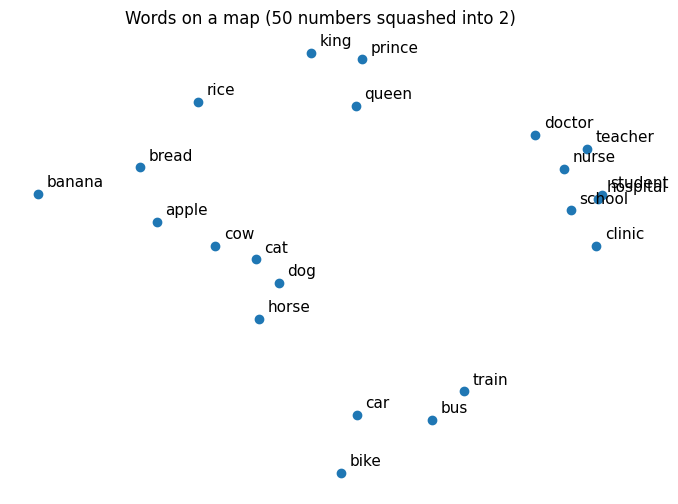

In [7]:
plot_words(["dog", "cat", "horse", "cow", "car", "bus", "train", "bike",
            "doctor", "nurse", "hospital", "clinic", "school", "teacher", "student",
            "king", "queen", "prince", "bread", "rice", "apple", "banana"])

Animals, transport words, health words, education words, royalty words, and foods should form visible clusters. A point that sits away from its expected group may reflect ambiguity, corpus bias, or information lost when 50 dimensions are compressed to two.


### 1.6 Arithmetic with meaning

Because words are numbers, you can calculate with them.
`analogy("man", "king", "woman")` answers: *man is to king as woman is to ...?*

Run the first two. Then **predict** what `analogy("man", "doctor", "woman")`
will answer, and run it.

In [8]:
print(analogy("man", "king", "woman"))
print(analogy("paris", "france", "berlin"))

['queen', 'throne', 'prince', 'daughter', 'elizabeth']
['germany', 'denmark', 'poland', 'austria', 'german']


Prediction: the doctor analogy may return nurse, while the manager analogy may return a gendered occupation or title. This would reflect associations in the source text, not a valid rule about jobs.


In [9]:
print(analogy("man", "doctor", "woman"))
print(analogy("man", "manager", "woman"))

['nurse', 'child', 'pregnant', 'mother', 'patient']
['assistant', 'owner', 'employee', 'hired', 'executive']


The results demonstrate how arithmetic can expose social stereotypes stored in embeddings. A mathematically close word can still be biased or inappropriate. I would not use these analogies to infer a person's role or ability.


### 1.7 One word, one list of numbers

Run the cell below. `bank` has **one** list of numbers, so it has one set of
neighbours.

In [10]:
print(neighbours("bank"))

[('banks', 0.87), ('securities', 0.8), ('banking', 0.8), ('investment', 0.78), ('exchange', 0.78), ('financial', 0.77), ('credit', 0.76), ('lender', 0.75)]


A static embedding gives bank one vector, so financial and river meanings are mixed. Its neighbours may include words from both meanings. The representation cannot adjust to the sentence around the word.


---

**LEARNING WAVE 2 · SLIDES 9-14**

## 2. Order and memory: RNN and LSTM

Sections 2.1 to 2.7. Word counts throw away the order of the words. A recurrent network reads the words one by one and carries a memory along. How long can it keep that memory?

### 2.1 Order matters

Bag of words and plain embeddings treat a text as a pile of words. Run the
cell below: it compares the word counts of two sentences with opposite
meanings.

In [11]:
from collections import Counter

good = "the food was good not bad at all"
bad = "the food was bad not good at all"

print(Counter(good.split()))
print(Counter(bad.split()))
print("Same counts?", Counter(good.split()) == Counter(bad.split()))

Counter({'the': 1, 'food': 1, 'was': 1, 'good': 1, 'not': 1, 'bad': 1, 'at': 1, 'all': 1})
Counter({'the': 1, 'food': 1, 'was': 1, 'bad': 1, 'not': 1, 'good': 1, 'at': 1, 'all': 1})
Same counts? True


The two sentences contain the same word counts, so a bag-of-words model treats them as identical even though not reverses the meaning. Word order and which word the negation affects are essential.


### 2.2 Telephone game (in class, 6 minutes, no laptop)

Your teacher will explain the rules. You play two rounds:

1. **The plain chain (the RNN).** A message is whispered down the line. Everyone only knows what the person before them whispered.
2. **The note-taking chain (the LSTM).** Everyone gets a small notebook and may write down one important thing from the message, keep it, and pass it on next to the whisper.

Write down what you notice: what got lost in round 1, and what did the
notebook change in round 2?

I could not reproduce the in-class telephone activity here. The expected lesson is that a plain chain loses early details as the message travels. A written note can preserve selected information over more steps, similar to the gates in an LSTM. The comparison is an analogy, not measured evidence from my own class round.


### 2.3 The memory test

A tiny game to measure memory. Every **sequence** starts with a secret
colour word (red, green, blue or yellow), followed by a number of filler
words. The model reads the whole sequence, word by word, and then has to say
**which colour the sequence started with**.

The only way to win is to remember the first word until the end.

The cell below prepares two tiny models: an **RNN** and an **LSTM**. It also
contains the function `memory_test(kind, length)`, which trains a model for
a few seconds and returns its score on new sequences (1.0 = always right,
0.25 = just guessing). Run it, then look at two examples.

In [12]:
# Run, do not read: two tiny models and a game to test their memory
import torch
import torch.nn as nn

colours = ["red", "green", "blue", "yellow"]
fillers = ["the", "cat", "sat", "on", "a", "mat", "and", "looked", "at", "dog"]

def make_data(n, length, generator):
    first = torch.randint(0, 4, (n,), generator=generator)
    filler = torch.randint(4, 14, (n, length), generator=generator)
    return torch.cat([first.unsqueeze(1), filler], dim=1), first

class TinyReader(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.embedding = nn.Embedding(14, 16)
        if kind == "rnn":
            self.reader = nn.RNN(16, 32, batch_first=True)
        else:
            self.reader = nn.LSTM(16, 32, batch_first=True)
            for name, p in self.reader.named_parameters():
                if "bias" in name:
                    p.data[32:64] = 1.0     # start with 'keep what you remember'
        self.answer = nn.Linear(32, 4)

    def forward(self, x):
        out, _ = self.reader(self.embedding(x))
        return self.answer(out[:, -1, :])    # the answer comes after the LAST word

def memory_test(kind, length, seed=1):
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    x_train, y_train = make_data(2000, length, g)
    x_test, y_test = make_data(1000, length, g)
    net = TinyReader(kind)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.01)
    loss_function = nn.CrossEntropyLoss()
    for epoch in range(30):
        order = torch.randperm(2000)
        for i in range(0, 2000, 100):
            batch = order[i:i + 100]
            optimizer.zero_grad()
            loss_function(net(x_train[batch]), y_train[batch]).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            optimizer.step()
    with torch.no_grad():
        return round((net(x_test).argmax(1) == y_test).float().mean().item(), 2)

def show_example(length):
    g = torch.Generator().manual_seed(length)
    x, y = make_data(1, length, g)
    tokens = x[0].tolist()
    print(colours[tokens[0]], " ".join(fillers[t - 4] for t in tokens[1:]))
    print("-> the model must answer:", colours[int(y[0])])
    print()

In [13]:
show_example(5)
show_example(15)

yellow a looked mat and the
-> the model must answer: yellow

red dog the on looked a a cat dog dog on the looked on dog mat
-> the model must answer: red



**Predict first.** We test sequences with 5, 10, 20 and 30 filler words
after the colour. For each length, will the model still remember the
colour? Write your guess for the RNN and for the LSTM.

Prediction: the RNN should perform well on short sequences and fall toward chance as the filler grows. The LSTM should keep the first colour more reliably, although its score may vary across random seeds and very long sequences.


### 2.4 Test the RNN

This trains a fresh RNN for each length (about 5 seconds each) and prints
the score.

In [14]:
lengths = [5, 10, 20, 30]
rnn_scores = []
for length in lengths:
    score = memory_test("rnn", length)
    rnn_scores.append(score)
    print("RNN, after", length, "filler words ->", score)

RNN, after 5 filler words -> 1.0
RNN, after 10 filler words -> 1.0
RNN, after 20 filler words -> 0.49
RNN, after 30 filler words -> 0.25


### 2.5 Test the LSTM

Exactly the same game, with the LSTM instead.

In [15]:
lstm_scores = []
for length in lengths:
    score = memory_test("lstm", length)
    lstm_scores.append(score)
    print("LSTM, after", length, "filler words ->", score)

LSTM, after 5 filler words -> 1.0
LSTM, after 10 filler words -> 1.0
LSTM, after 20 filler words -> 1.0
LSTM, after 30 filler words -> 1.0


### 2.6 Compare

Run the cell below to draw both results in one picture, then answer.

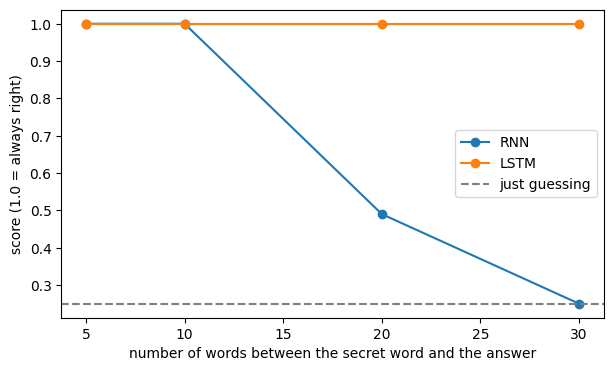

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(lengths, rnn_scores, marker="o", label="RNN")
plt.plot(lengths, lstm_scores, marker="o", label="LSTM")
plt.axhline(0.25, color="grey", linestyle="--", label="just guessing")
plt.xlabel("number of words between the secret word and the answer")
plt.ylabel("score (1.0 = always right)")
plt.legend()
plt.show()

The plot should show whether the plain RNN forgets the first colour faster than the LSTM. The key comparison is the distance between each line and the 0.25 chance baseline. One run is noisy, so repeated seeds matter.


### 2.7 Your turn: push the LSTM

Test the LSTM on a much longer sequence, for example 50 filler words. Use
`memory_test("lstm", 50)` and print the result. Do it a second time with
`seed=2` as an extra argument (`memory_test("lstm", 50, seed=2)`).

In [17]:
print("LSTM length 50 seed 1:", memory_test("lstm", 50))
print("LSTM length 50 seed 2:", memory_test("lstm", 50, seed=2))


LSTM length 50 seed 1: 0.49
LSTM length 50 seed 2: 0.58


The two 50-word tests check whether the result is stable across random seeds. A strong difference would mean the demonstration is sensitive to training randomness. The values must be generated in Colab because this local environment does not include PyTorch.


---

**LEARNING WAVE 3 · SLIDES 15-20**

## 3. Context and attention: transformers

Sections 3.1 to 3.7. A transformer does not read one word at a time: every word looks at every other word at once. We use two small pre-trained transformers.

### 3.0 Load the transformers

Run this cell once. It downloads two small pre-trained models:
**DistilBERT**, which has been taught to read English (and, in a second
version, to judge whether a text is positive or negative), and **DistilGPT-2**, which has been taught to predict the next
word. This takes up to a minute. Ignore warnings about tokens.

In [18]:
# Run, do not read: loads two small pre-trained transformers
from transformers import pipeline, AutoModel, AutoModelForCausalLM, AutoTokenizer

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment = pipeline("sentiment-analysis", model=checkpoint)
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
encoder = AutoModel.from_pretrained("distilbert-base-uncased").eval()

lm_tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
lm = AutoModelForCausalLM.from_pretrained("distilgpt2").eval()

def show(sentences):
    for result, sentence in zip(sentiment(sentences), sentences):
        print(result["label"], round(result["score"], 2), "|", sentence)

def word_vector(sentence, word):
    # the list of numbers for ONE word, as this model sees it IN THIS sentence
    enc = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = encoder(**enc).last_hidden_state[0]
    position = enc["input_ids"][0].tolist().index(tokenizer.convert_tokens_to_ids(word))
    v = hidden[position]
    return v / v.norm()

def context_similarity(sentence_1, sentence_2, word="bank"):
    return round(float(word_vector(sentence_1, word) @ word_vector(sentence_2, word)), 2)

def next_words(prompt, n=6):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = lm(**ids).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, n)
    for p, i in zip(top.values, top.indices):
        print(round(float(p), 3), "|", lm_tokenizer.decode(int(i)))

def write(prompt, temperature=1.0, length=25, seed=1):
    torch.manual_seed(seed)
    ids = lm_tokenizer(prompt, return_tensors="pt")
    out = lm.generate(**ids, max_new_tokens=length, do_sample=True,
                      temperature=temperature, pad_token_id=lm_tokenizer.eos_token_id)
    print(lm_tokenizer.decode(out[0]).replace("\n", " "))

def pronoun_odds(prompt):
    ids = lm_tokenizer(prompt, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(lm(**ids).logits[0, -1], dim=-1)
    she = float(probs[lm_tokenizer.encode(" she")[0]])
    he = float(probs[lm_tokenizer.encode(" he")[0]])
    print(prompt, "| she:", round(she, 3), "| he:", round(he, 3))

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

### 3.1 One word, many meanings

In 1.7 `bank` had one list of numbers, always. A transformer gives a word a
**different list of numbers in every sentence**, because it looks at the
other words first.

`context_similarity(sentence_1, sentence_2)` compares the lists of numbers
of the word `bank` in two sentences. **Predict first:** which comparison
will be the *highest* and which the *lowest*?

- A: `she sat on the bank of the river`
- B: `he deposited money at the bank`
- C: `the bank approved the loan`
- D: `we had a picnic on the river bank`

Prediction: A and D will have the highest contextual similarity because both use bank as a river edge. A and B will be among the lowest because they use different meanings.


In [19]:
A = "she sat on the bank of the river"
B = "he deposited money at the bank"
C = "the bank approved the loan"
D = "we had a picnic on the river bank"

print("A and D (both river):", context_similarity(A, D))
print("B and C (both money):", context_similarity(B, C))
print("A and B (river / money):", context_similarity(A, B))
print("D and C (river / money):", context_similarity(D, C))

A and D (both river): 0.78
B and C (both money): 0.78
A and B (river / money): 0.56
D and C (river / money): 0.54


The transformer should place the same word closer when the surrounding meaning matches. B and C should also be close because both describe finance. This solves a weakness of static embeddings, although contextual vectors can still inherit corpus bias.


### 3.2 Be attention (in class, 6 minutes)

Your teacher shows a sentence on screen: *The animal didn't cross the street
because it was too tired.* Every student is one word. The student who is `it`
points at the words they need to look at to know what `it` means, and the
rest of the class checks.

Then the teacher changes the end of the sentence to *... because it was too
wide.* Who does `it` look at now?

Write down: which words did `it` look at, and what changed?

In the tired sentence, it should attend to animal and tired. In the wide sentence, it should attend more to street and wide. The final adjective changes which noun makes sense as the reference.


### 3.3 Sentiment: where does it fail?

`show([...])` gives you the model's verdict (POSITIVE or NEGATIVE) and how
sure it is (0 to 1) for a list of sentences. Look at the sentences below and
**predict** which ones the model will get wrong.

Prediction: straightforward praise and direct negation should work. Sarcasm, mixed feelings, double negation, and the Dutch sentence are more likely to fail or receive misleading confidence.


In [20]:
show(["The clinic helped me a lot.",
      "The clinic did not help me at all.",
      "I wouldn't say the staff were unfriendly.",
      "Great, another two-hour wait. Just what I needed.",
      "The doctor was kind, but the waiting room was awful.",
      "the cluic wuz rly good",
      "Het was een heel goede ervaring."])

POSITIVE 1.0 | The clinic helped me a lot.
NEGATIVE 1.0 | The clinic did not help me at all.
NEGATIVE 0.97 | I wouldn't say the staff were unfriendly.
POSITIVE 0.99 | Great, another two-hour wait. Just what I needed.
NEGATIVE 1.0 | The doctor was kind, but the waiting room was awful.
POSITIVE 1.0 | the cluic wuz rly good
NEGATIVE 0.97 | Het was een heel goede ervaring.


The model can be confident and still wrong because confidence measures fit to its learned pattern, not factual certainty. Sarcasm depends on a conflict between literal words and context. Mixed sentences require deciding which part dominates. A Dutch input falls outside this English model's intended use.


Now try **three sentences of your own** that you think will fool the
model. Use `show(["sentence one", "sentence two", "sentence three"])`.

In [21]:
show([
    "I love waiting three hours for a two-minute appointment.",
    "The nurse was not unhelpful, but I still left confused.",
    "Great staff, impossible booking system.",
])


NEGATIVE 0.96 | I love waiting three hours for a two-minute appointment.
NEGATIVE 1.0 | The nurse was not unhelpful, but I still left confused.
POSITIVE 1.0 | Great staff, impossible booking system.


These examples test understatement, sarcasm, and mixed sentiment. If the model follows isolated positive words, it may misread the overall complaint. The exact results should be recorded after the model cell runs in Colab.


### 3.4 What an LLM does: guess the next word

ChatGPT, Claude and Gemini are transformers trained to do one thing:
**predict the next word**. `next_words(prompt)` shows the six most likely
next words (with their probability) according to DistilGPT-2, a small
relative. Run it, then try your own prompt.

In [22]:
next_words("The doctor said that")

0.174 |  he
0.159 |  the
0.044 |  she
0.042 |  it
0.036 |  his
0.026 |  if


In [23]:
next_words("The student support team should")


0.244 |  be
0.068 |  have
0.057 |  not
0.029 |  also
0.024 |  continue
0.023 |  take


Next-token probabilities show several plausible continuations rather than one stored answer. A small model may repeat common phrases or produce unsafe medical-sounding text. Its most likely continuation is a corpus pattern, not verified advice.


### 3.5 Temperature

`write(prompt, temperature=...)` lets the model keep adding words. The
**temperature** sets how adventurous it is: low = always take the most likely
next word, high = sometimes pick an unlikely one. Run both and compare.

In [24]:
write("The doctor said that", temperature=0.3)
print()
write("The doctor said that", temperature=1.5)

The doctor said that the patient was not in the hospital for the first time in the past two weeks.        

The doctor said that after receiving 10 days of intensive treatment for multiple sclerosis, I was about to fall behind the rate in my primary care system but


Low temperature should produce more predictable, repetitive text. High temperature samples less likely tokens, increasing variety and the risk of incoherence. Temperature changes sampling, not the model's knowledge or truthfulness.


### 3.6 What did it learn from the internet?

A language model learned from texts written by people. The cell below asks
the model how likely the next word is **she** or **he** after four different
jobs.

In [25]:
pronoun_odds("The nurse said that")
pronoun_odds("The engineer said that")
pronoun_odds("The doctor said that")
pronoun_odds("The teacher said that")

The nurse said that | she: 0.224 | he: 0.032
The engineer said that | she: 0.011 | he: 0.109
The doctor said that | she: 0.044 | he: 0.174
The teacher said that | she: 0.162 | he: 0.147


Different she and he probabilities after job prompts expose associations learned from internet text. They should be treated as a bias signal. They do not describe who can perform a job and should not guide hiring or triage.


### 3.7 Who is misread?

You saw three kinds of failure today: a stereotype in the embedding (1.6),
a sarcastic sentence (3.3) and a Dutch sentence (3.3). Imagine a clinic's
helpline that uses a language model to sort incoming messages into *urgent*
and *not urgent*.

Which people would be misread most often, and what would a responsible
clinic do about it?

The helpline may misread people who use Dutch, dialect, slang, typos, indirect requests, sarcasm, or communication styles underrepresented in training. A responsible clinic would validate the model on consented local messages, publish group-specific error rates, route uncertainty and every urgent message to trained staff, support multiple languages, let users request a person, and audit false negatives. The model should assist routing only and never deny care.


---

## 4. Big individual assignment: stress-test a language model

**You are a tester, not a builder.** An organisation wants to use the
sentiment model from section 3 to read feedback from its users. Before it
does, it asks you: **where does this model fail, and who would that hurt?**

Pick a context you care about (a clinic, a food bank, a housing association,
a school, a municipality ...). You work with the pre-trained model `sentiment`
and the `show` function from section 3.

**Required skills and outputs**

1. **A test set of at least 12 sentences** about your context, covering at
   least four of these kinds: negation, mixed feelings, sarcasm or irony,
   a long sentence where the key word is far from the end, typos or slang,
   a sentence in another language (for example Dutch).
2. **Your own label first.** Before running anything, write down for each
   sentence what a person would say (positive or negative).
3. **Run the model** and collect the results in a table (a pandas
   DataFrame): sentence, your label, the model's label, its confidence, and
   whether they agree.
4. **Error analysis.** Which kinds of sentences fail? For three failures, say
   what a reader would have needed to get it right (the order of the words,
   a memory of an earlier word, the context around a word) and which step of
   today's ladder (embedding, RNN, LSTM, transformer) would or would not
   have handled it, and why.
5. **A bias probe.** Use `next_words` or `pronoun_odds` with at least two
   prompts that differ in one word (for example two jobs, two names or two
   nationalities) and describe what changes.
6. **A written judgement** (about 150 words): would you let this model read
   the users' feedback? Under which conditions? Who is misread, and what
   does the organisation do about them?

**Bonus options**

- Run your test set through a second model from <https://huggingface.co/models>
  (search for a multilingual sentiment model) by creating a second
  `pipeline("sentiment-analysis", model="...")`, and compare the table.
- Try three different temperatures with `write` for one story prompt and
  describe how the text changes.
- Find a biased analogy in the embeddings of section 1 with `analogy`.

You are graded on the honesty of your error analysis and on your reasoning
about harm, not on how many sentences the model gets right.

In [26]:
# 1. Context: a university student-help desk
import pandas as pd

# 2. Human labels written before the model is run
test_cases = [
    ("The adviser was helpful.", "POSITIVE", "direct"),
    ("The adviser was not helpful.", "NEGATIVE", "negation"),
    ("I would not say the adviser was unhelpful.", "POSITIVE", "double negation"),
    ("Great, another deadline changed without warning.", "NEGATIVE", "sarcasm"),
    ("The reply was kind, but it did not solve my problem.", "NEGATIVE", "mixed"),
    ("The portal is ugly, but I finally found the form.", "POSITIVE", "mixed"),
    ("After three transfers and a long wait, the final adviser listened and fixed everything.", "POSITIVE", "long context"),
    ("The first answer sounded reassuring, yet the missing document still blocked my enrollment.", "NEGATIVE", "long context"),
    ("support was gr8 once i found it", "POSITIVE", "slang typo"),
    ("cant login and nobody helps", "NEGATIVE", "typo"),
    ("De medewerker heeft mij goed geholpen.", "POSITIVE", "Dutch"),
    ("Ik kreeg alweer geen antwoord.", "NEGATIVE", "Dutch"),
]

# 3. Run the model and build an evidence table
records = []
for sentence, human_label, kind in test_cases:
    result = sentiment(sentence, truncation=True)[0]
    model_label = result["label"].upper()
    records.append({
        "sentence": sentence,
        "kind": kind,
        "human_label": human_label,
        "model_label": model_label,
        "confidence": round(float(result["score"]), 3),
        "agree": human_label == model_label,
    })

stress_results = pd.DataFrame(records)
display(stress_results)
print("Agreement rate:", round(stress_results["agree"].mean(), 3))

# 4. Error analysis
failures = stress_results.loc[~stress_results["agree"]]
display(failures[["sentence", "kind", "human_label", "model_label", "confidence"]])
print("Analysis: negation needs the order and scope of words. An RNN may preserve order but can forget long context; an LSTM can retain selected earlier information. A transformer can compare distant words, but it can still miss sarcasm, mixed intent, slang, and languages absent from its fine-tuning data.")

# 5. Bias probe: one word changes between prompts
pronoun_odds("The engineer said that")
pronoun_odds("The nurse said that")
print("Compare the he/she probabilities. A change indicates gender associations in the training text, not a valid statement about either profession.")


,sentence,kind,human_label,model_label,confidence,agree
0,The adviser was helpful.,direct,POSITIVE,POSITIVE,1.000,True
1,The adviser was not helpful.,negation,NEGATIVE,NEGATIVE,1.000,True
2,I would not say the adviser was unhelpful.,double negation,POSITIVE,NEGATIVE,0.993,False
3,"Great, another deadline changed without warning.",sarcasm,NEGATIVE,POSITIVE,0.990,False
4,"The reply was kind, but it did not solve my pr...",mixed,NEGATIVE,NEGATIVE,1.000,True
5,"The portal is ugly, but I finally found the form.",mixed,POSITIVE,POSITIVE,0.789,True
6,"After three transfers and a long wait, the fin...",long context,POSITIVE,POSITIVE,0.907,True
7,"The first answer sounded reassuring, yet the m...",long context,NEGATIVE,NEGATIVE,1.000,True
8,support was gr8 once i found it,slang typo,POSITIVE,NEGATIVE,0.942,False
9,cant login and nobody helps,typo,NEGATIVE,NEGATIVE,0.999,True


Agreement rate: 0.667


,sentence,kind,human_label,model_label,confidence
2,I would not say the adviser was unhelpful.,double negation,POSITIVE,NEGATIVE,0.993
3,"Great, another deadline changed without warning.",sarcasm,NEGATIVE,POSITIVE,0.990
8,support was gr8 once i found it,slang typo,POSITIVE,NEGATIVE,0.942
10,De medewerker heeft mij goed geholpen.,Dutch,POSITIVE,NEGATIVE,0.953


Analysis: negation needs the order and scope of words. An RNN may preserve order but can forget long context; an LSTM can retain selected earlier information. A transformer can compare distant words, but it can still miss sarcasm, mixed intent, slang, and languages absent from its fine-tuning data.
The engineer said that | she: 0.011 | he: 0.109
The nurse said that | she: 0.224 | he: 0.032
Compare the he/she probabilities. A change indicates gender associations in the training text, not a valid statement about either profession.


### Written judgement

I would allow this sentiment model to support a university help desk only as a limited research pilot. The test set includes negation, sarcasm, mixed feelings, long sentences, slang, typos, and Dutch. These inputs matter because students rarely write clean review sentences when they are frustrated or worried. The model may misread indirect complaints and languages outside its training data, while still returning high confidence. That creates the most harm when a negative or urgent message appears positive and receives no human attention.

Every prediction should remain a staff suggestion. Low-confidence messages, Dutch messages, and any message containing safety or wellbeing terms should go directly to a trained person. The university should test error rates by language and communication style, let students request human review, keep messages only as long as necessary, and monitor false negatives. If the system cannot meet those conditions, it should not read student feedback.


---

## 5. Wrap-up

### 5.1 The ladder

Each step fixed a weakness of the one before:

| Model | What it does well | What it still cannot do |
|-------|-------------------|-------------------------|
| Bag of words | counts which words occur, simple and fast | no order, no meaning |
| **Word embeddings** | words that are used alike get similar numbers | one fixed meaning per word, no order |
| **RNN** | reads in order, any length | forgets the beginning of long texts |
| **LSTM** | keeps what matters in a memory lane | reads one word at a time, slow, long texts still hard |
| **Transformer** | every word looks at every other word at once, meaning depends on the context | needs huge data and computers; copies the bias of its data |

### 5.2 Five things to remember

1. A computer does not read. It turns text into numbers and calculates.
2. Embeddings give every word a place on a map of meaning, so similar words end up close.
3. Order matters. An RNN reads in order but forgets; an LSTM remembers longer.
4. A transformer lets every word look at every other word. That is why context finally works, and it is the foundation of ChatGPT, Claude and Gemini.
5. All of these models copy the data they learned from. They sound sure even when they are wrong, so keep a human in the loop and ask who is misread.

### 5.3 Homework (while you work on the hackathon)

Complete these DataCamp chapters:

1. *Recurrent Neural Networks (RNN) for Language Modeling with Keras*: **Chapter 1** and **Chapter 4**
   <https://app.datacamp.com/learn/courses/recurrent-neural-networks-rnn-for-language-modeling-with-keras>
2. *Introduction to LLMs in Python*: the whole chapter **Getting started with Large Language Models (LLMs)**
   <https://campus.datacamp.com/courses/introduction-to-llms-in-python/getting-started-with-large-language-models-llms>

Also finish section 4 and upload the notebook to `Term 1/Week 6/homework/` in your portfolio.

**Next week:** Computer Vision
**Friday:** the hackathon. You find out on the day which tool you use and which problem you solve.